<a href="https://colab.research.google.com/github/deepak-kumar-da/smart-comment-classifier/blob/main/notebooks/08_comparative_evaluation_and_error_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
    multilabel_confusion_matrix, roc_auc_score,
    average_precision_score
)

BASE = "/content/drive/MyDrive/Smart_Comment_Classifier"
REPORTS = f"{BASE}/datasets/reports"
OUTPUTS = f"{BASE}/outputs"

os.makedirs(REPORTS, exist_ok=True)
os.makedirs(OUTPUTS, exist_ok=True)

TOX_LABELS = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

spam_path = f"{REPORTS}/notebook_07_spam_test_predictions.csv"
tox_path = f"{REPORTS}/notebook_07_toxicity_test_predictions.csv"

assert os.path.exists(spam_path), f"Missing file: {spam_path}"
assert os.path.exists(tox_path), f"Missing file: {tox_path}"

spam = pd.read_csv(spam_path)
tox = pd.read_csv(tox_path)

print("Spam predictions:", spam.shape)
print("Toxicity predictions:", tox.shape)

display(spam.head(3))
display(tox.head(3))

Mounted at /content/drive
Spam predictions: (349, 4)
Toxicity predictions: (31855, 19)


,text,label,predicted_label,spam_probability
0,want to win borderlands the pre-sequel? check ...,1,1,0.995483
1,Hi everyone! Do you like music? Then why not c...,1,1,0.997893
2,CHECK OUT THIS DOPE CHANNEL! phenomenallyri...,1,1,0.996575


,text,toxic,severe_toxic,obscene,threat,insult,identity_hate,pred_toxic,prob_toxic,pred_severe_toxic,prob_severe_toxic,pred_obscene,prob_obscene,pred_threat,prob_threat,pred_insult,prob_insult,pred_identity_hate,prob_identity_hate
0,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,0,0.002489,0,0.000005,0,0.000395,0,0.000062,0,0.000200,0,0.000126
1,"""\n\nCongratulations from me as well, use the ...",0,0,0,0,0,0,0,0.001177,0,0.000005,0,0.000300,0,0.000054,0,0.000189,0,0.000121
2,alignment on this subject and which are contra...,0,0,0,0,0,0,0,0.004756,0,0.000007,0,0.000539,0,0.000085,0,0.000303,0,0.000155


In [3]:
# validate prediction file

required_spam = [
    "text", "label", "predicted_label", "spam_probability"
]

required_tox = (
    ["text"] + TOX_LABELS
    + [f"pred_{x}" for x in TOX_LABELS]
    + [f"prob_{x}" for x in TOX_LABELS]
)

assert all(c in spam.columns for c in required_spam), \
    "Spam prediction file is missing required columns."

assert all(c in tox.columns for c in required_tox), \
    "Toxicity prediction file is missing required columns."

spam = spam.dropna(subset=required_spam).copy()
tox = tox.dropna(subset=required_tox).copy()

for col in ["label", "predicted_label"]:
    spam[col] = spam[col].astype(int)

for col in TOX_LABELS + [f"pred_{x}" for x in TOX_LABELS]:
    tox[col] = tox[col].astype(int)

# Convert probabilities to numeric separately to avoid KeyError
spam["spam_probability"] = pd.to_numeric(spam["spam_probability"], errors="coerce")
for col in [f"prob_{x}" for x in TOX_LABELS]:
    tox[col] = pd.to_numeric(tox[col], errors="coerce")

spam = spam.dropna(subset=["spam_probability"]).copy()
tox = tox.dropna(subset=[f"prob_{x}" for x in TOX_LABELS]).copy()

print("Validated spam rows:", len(spam))
print("Validated toxicity rows:", len(tox))

print("\nSpam labels:")
print(spam["label"].value_counts().sort_index())

print("\nToxicity positive labels:")
print(tox[TOX_LABELS].sum())

Validated spam rows: 349
Validated toxicity rows: 31855

Spam labels:
label
0    181
1    168
Name: count, dtype: int64

Toxicity positive labels:
toxic            3043
severe_toxic      317
obscene          1681
threat             94
insult           1567
identity_hate     279
dtype: int64


In [4]:
# spam metrics

y_true_spam = spam["label"].values
y_pred_spam = spam["predicted_label"].values
spam_probs = spam["spam_probability"].values

spam_metrics = {
    "accuracy": float(accuracy_score(y_true_spam, y_pred_spam)),
    "macro_precision": float(precision_score(
        y_true_spam, y_pred_spam, average="macro", zero_division=0
    )),
    "macro_recall": float(recall_score(
        y_true_spam, y_pred_spam, average="macro", zero_division=0
    )),
    "macro_f1": float(f1_score(
        y_true_spam, y_pred_spam, average="macro", zero_division=0
    )),
    "spam_precision": float(precision_score(
        y_true_spam, y_pred_spam, pos_label=1, zero_division=0
    )),
    "spam_recall": float(recall_score(
        y_true_spam, y_pred_spam, pos_label=1, zero_division=0
    )),
    "spam_f1": float(f1_score(
        y_true_spam, y_pred_spam, pos_label=1, zero_division=0
    ))
}

try:
    spam_metrics["spam_roc_auc"] = float(
        roc_auc_score(y_true_spam, spam_probs)
    )
    spam_metrics["spam_average_precision"] = float(
        average_precision_score(y_true_spam, spam_probs)
    )
except ValueError:
    spam_metrics["spam_roc_auc"] = None
    spam_metrics["spam_average_precision"] = None

print(json.dumps(spam_metrics, indent=2))

print("\nClassification report:")
print(classification_report(
    y_true_spam,
    y_pred_spam,
    target_names=["Not spam", "Spam"],
    zero_division=0
))

{
  "accuracy": 0.9742120343839542,
  "macro_precision": 0.9756178141932074,
  "macro_recall": 0.9734280452512496,
  "macro_f1": 0.9741270664986286,
  "spam_precision": 0.9937888198757764,
  "spam_recall": 0.9523809523809523,
  "spam_f1": 0.9726443768996961,
  "spam_roc_auc": 0.9944751381215469,
  "spam_average_precision": 0.9951311457896277
}

Classification report:
              precision    recall  f1-score   support

    Not spam       0.96      0.99      0.98       181
        Spam       0.99      0.95      0.97       168

    accuracy                           0.97       349
   macro avg       0.98      0.97      0.97       349
weighted avg       0.97      0.97      0.97       349



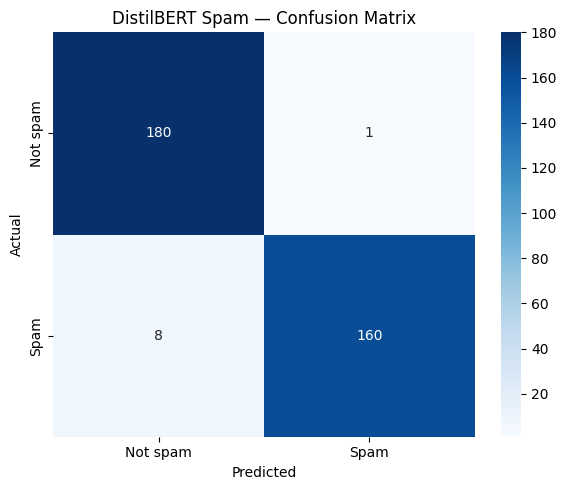

True negatives: 180
False positives: 1
False negatives: 8
True positives: 160


In [5]:
# spam confusion matrix

cm_spam = confusion_matrix(y_true_spam, y_pred_spam)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_spam,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not spam", "Spam"],
    yticklabels=["Not spam", "Spam"]
)
plt.title("DistilBERT Spam — Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig(f"{OUTPUTS}/08_spam_confusion_matrix.png", dpi=150)
plt.show()

tn, fp, fn, tp = cm_spam.ravel()

print("True negatives:", tn)
print("False positives:", fp)
print("False negatives:", fn)
print("True positives:", tp)

In [6]:
# extract spam false positive and false negative

spam["error_type"] = np.select(
    [
        (spam["label"] == 0) & (spam["predicted_label"] == 1),
        (spam["label"] == 1) & (spam["predicted_label"] == 0)
    ],
    [
        "False Positive",
        "False Negative"
    ],
    default="Correct"
)

spam_errors = spam[spam["error_type"] != "Correct"].copy()

print("Total spam test errors:", len(spam_errors))
print("\nError counts:")
print(spam_errors["error_type"].value_counts())

print("\nFalse positives — legitimate comments predicted as spam:")
display(
    spam_errors[spam_errors["error_type"] == "False Positive"]
    [["text", "label", "predicted_label", "spam_probability"]]
    .head(25)
)

print("\nFalse negatives — spam comments predicted as legitimate:")
display(
    spam_errors[spam_errors["error_type"] == "False Negative"]
    [["text", "label", "predicted_label", "spam_probability"]]
    .head(25)
)

spam_errors.to_csv(
    f"{REPORTS}/notebook_08_spam_errors.csv",
    index=False
)

Total spam test errors: 9

Error counts:
error_type
False Negative    8
False Positive    1
Name: count, dtype: int64

False positives — legitimate comments predicted as spam:


,text,label,predicted_label,spam_probability
41,hay my is honesty wright i am 12year old i lo...,0,1,0.992452



False negatives — spam comments predicted as legitimate:


,text,label,predicted_label,spam_probability
109,Yea stil the best WK song ever<br />Thumbs up ...,1,0,0.002543
136,Wow justin Bieber is Better thats why when he...,1,0,0.006531
137,Can i get views and subscribers for no reason? 😅﻿,1,0,0.370006
143,I like This Comment and do not kill :P﻿,1,0,0.027324
211,This guy win dollars sleeping... m m m he love...,1,0,0.001953
311,me shaking my sexy ass on my channel enjoy ^_^ ﻿,1,0,0.018198
328,if eminem gets 1 penny per view he would have ...,1,0,0.003374
343,He gets more views but has less subscribers lol,1,0,0.015599


/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:576: RuntimeWarning: Mean of empty slice
  avg = a.mean(axis, **keepdims_kw)
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


,confidence_band,comments,accuracy
0,Low,0,NaN
1,Moderate,2,0.500000
2,High,2,1.000000
3,Very high,345,0.976812


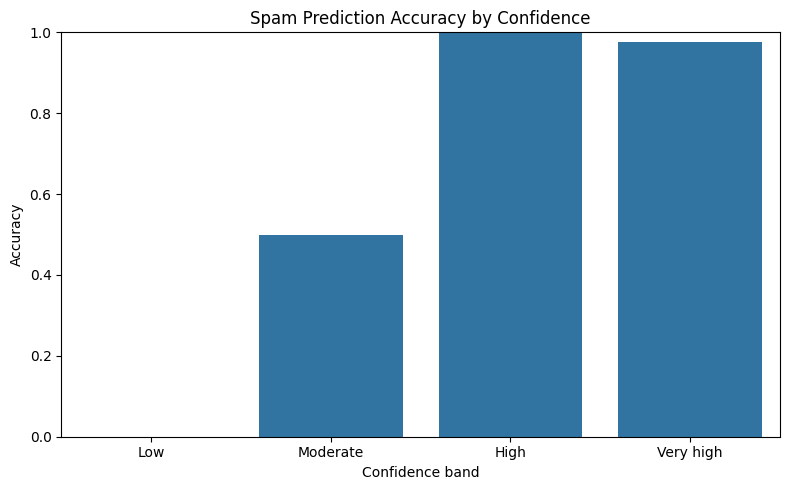

In [7]:
# spam confidence analysis

spam["confidence"] = np.maximum(
    spam["spam_probability"],
    1 - spam["spam_probability"]
)

spam["confidence_band"] = pd.cut(
    spam["confidence"],
    bins=[0.0, 0.60, 0.80, 0.90, 1.001],
    labels=["Low", "Moderate", "High", "Very high"],
    include_lowest=True
)

confidence_summary = spam.groupby(
    "confidence_band", observed=False
).agg(
    comments=("text", "count"),
    accuracy=("label", lambda x: accuracy_score(
        x, spam.loc[x.index, "predicted_label"]
    ))
).reset_index()

display(confidence_summary)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=confidence_summary,
    x="confidence_band",
    y="accuracy"
)
plt.ylim(0, 1)
plt.title("Spam Prediction Accuracy by Confidence")
plt.xlabel("Confidence band")
plt.ylabel("Accuracy")
plt.tight_layout()
plt.savefig(f"{OUTPUTS}/08_spam_confidence_analysis.png", dpi=150)
plt.show()

In [8]:
# toxicity overall metrics

y_true_tox = tox[TOX_LABELS].values.astype(int)
y_pred_tox = tox[[f"pred_{x}" for x in TOX_LABELS]].values.astype(int)
y_prob_tox = tox[[f"prob_{x}" for x in TOX_LABELS]].values.astype(float)

tox_overall_metrics = {
    "macro_f1": float(f1_score(
        y_true_tox, y_pred_tox, average="macro", zero_division=0
    )),
    "micro_f1": float(f1_score(
        y_true_tox, y_pred_tox, average="micro", zero_division=0
    )),
    "weighted_f1": float(f1_score(
        y_true_tox, y_pred_tox, average="weighted", zero_division=0
    )),
    "exact_match_accuracy": float(accuracy_score(
        y_true_tox, y_pred_tox
    ))
}

print(json.dumps(tox_overall_metrics, indent=2))

{
  "macro_f1": 0.6557193880689568,
  "micro_f1": 0.7763546798029557,
  "weighted_f1": 0.7805381021528867,
  "exact_match_accuracy": 0.9240621566473081
}


In [9]:
# per category toxicity performance

tox_results = []

for i, label in enumerate(TOX_LABELS):
    y_true = y_true_tox[:, i]
    y_pred = y_pred_tox[:, i]
    y_prob = y_prob_tox[:, i]

    row = {
        "label": label,
        "support_positive": int(y_true.sum()),
        "precision": float(precision_score(
            y_true, y_pred, zero_division=0
        )),
        "recall": float(recall_score(
            y_true, y_pred, zero_division=0
        )),
        "f1": float(f1_score(
            y_true, y_pred, zero_division=0
        ))
    }

    try:
        row["roc_auc"] = float(roc_auc_score(y_true, y_prob))
        row["average_precision"] = float(
            average_precision_score(y_true, y_prob)
        )
    except ValueError:
        row["roc_auc"] = None
        row["average_precision"] = None

    tox_results.append(row)

tox_per_label = pd.DataFrame(tox_results)
display(tox_per_label.sort_values("f1"))

tox_per_label.to_csv(
    f"{REPORTS}/notebook_08_toxicity_per_label.csv",
    index=False
)

,label,support_positive,precision,recall,f1,roc_auc,average_precision
3,threat,94,0.431193,0.500000,0.463054,0.984035,0.378091
1,severe_toxic,317,0.419149,0.621451,0.500635,0.987802,0.418045
5,identity_hate,279,0.520767,0.584229,0.550676,0.988682,0.552387
4,insult,1567,0.730546,0.802808,0.764974,0.988533,0.824503
0,toxic,3043,0.847895,0.787709,0.816695,0.983627,0.900838
2,obscene,1681,0.813199,0.864961,0.838282,0.992726,0.907385


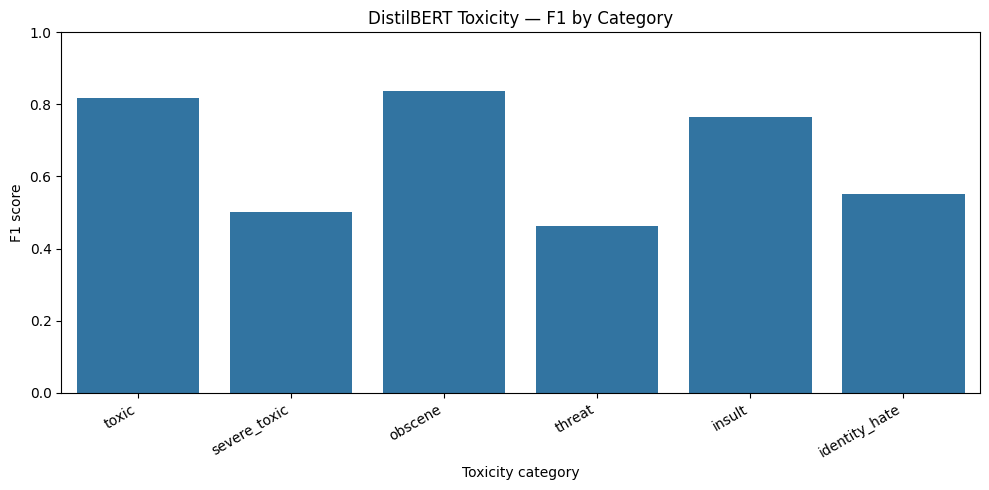

In [10]:
# toxicity f1 by category

plt.figure(figsize=(10, 5))

sns.barplot(
    data=tox_per_label,
    x="label",
    y="f1"
)

plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.title("DistilBERT Toxicity — F1 by Category")
plt.xlabel("Toxicity category")
plt.ylabel("F1 score")
plt.tight_layout()
plt.savefig(f"{OUTPUTS}/08_toxicity_category_f1.png", dpi=150)
plt.show()

In [11]:
# toxicity false positive and false negative

tox_error_rows = []

for i, label in enumerate(TOX_LABELS):
    actual = y_true_tox[:, i]
    predicted = y_pred_tox[:, i]

    fp_idx = np.where((actual == 0) & (predicted == 1))[0]
    fn_idx = np.where((actual == 1) & (predicted == 0))[0]

    for idx in fp_idx:
        tox_error_rows.append({
            "text": tox.iloc[idx]["text"],
            "label": label,
            "error_type": "False Positive",
            "actual": 0,
            "predicted": 1,
            "probability": y_prob_tox[idx, i]
        })

    for idx in fn_idx:
        tox_error_rows.append({
            "text": tox.iloc[idx]["text"],
            "label": label,
            "error_type": "False Negative",
            "actual": 1,
            "predicted": 0,
            "probability": y_prob_tox[idx, i]
        })

tox_errors = pd.DataFrame(tox_error_rows)

print("Total toxicity label errors:", len(tox_errors))
print("\nErrors by category and type:")
display(pd.crosstab(
    tox_errors["label"],
    tox_errors["error_type"]
))

print("\nFalse positives:")
display(
    tox_errors[tox_errors["error_type"] == "False Positive"].head(30)
)

print("\nFalse negatives:")
display(
    tox_errors[tox_errors["error_type"] == "False Negative"].head(30)
)

tox_errors.to_csv(
    f"{REPORTS}/notebook_08_toxicity_errors.csv",
    index=False
)

Total toxicity label errors: 3178

Errors by category and type:


error_type,False Negative,False Positive
label,,
identity_hate,116,150
insult,309,464
obscene,227,334
severe_toxic,120,273
threat,47,62
toxic,646,430



False positives:


,text,label,error_type,actual,predicted,probability
0,"""40, 25 January 2008 (UTC)\n\nNO, i am NOT bei...",toxic,False Positive,0,1,0.906865
1,No matter how many times I rethink it I cannot...,toxic,False Positive,0,1,0.940111
2,Where the Hell is Kisame's Section? \n\nWell? ...,toxic,False Positive,0,1,0.898196
3,Did you poop in your pants? —,toxic,False Positive,0,1,0.985206
4,People like you 359 take he virtual world way ...,toxic,False Positive,0,1,0.875004
5,"""\n\nAs do I, as do I. SVG is an evil, evil fo...",toxic,False Positive,0,1,0.942666
6,I guess you got a stalemate then? (\n\nI actau...,toxic,False Positive,0,1,0.877178
7,warning\nI read it. I'll consider it. I delete...,toxic,False Positive,0,1,0.935097
8,Ram it up ur ass very hard till ur eyes water,toxic,False Positive,0,1,0.999182
9,"""yes, I'm here too...\n""""High preformance gel ...",toxic,False Positive,0,1,0.928349



False negatives:


,text,label,error_type,actual,predicted,probability
430,"Bye! \n\nDon't look, come or think of comming ...",toxic,False Negative,1,0,0.100152
431,"""\n\nUNBLOCK ME OR I'LL GET MY LAWYERS ON TO Y...",toxic,False Negative,1,0,0.022090
432,Add Mobile porn as additional WP:ALSO link,toxic,False Negative,1,0,0.019053
433,Curse \nWikipedia has no respect for God. \nWi...,toxic,False Negative,1,0,0.687172
434,Muslim Men Harassment of MM page \n\nIt is ama...,toxic,False Negative,1,0,0.781823
435,Tried to be productive (look at my contributio...,toxic,False Negative,1,0,0.558601
436,"Get off your high horse, or block me.",toxic,False Negative,1,0,0.710831
437,What a joker you are. European parliament has ...,toxic,False Negative,1,0,0.804641
438,I AM GAY\nLove\n \nI AM GAY\nLove\n \nI AM G...,toxic,False Negative,1,0,0.592691
439,"""\n\nNo! This is a GROUP EFFORT! Wikipedia i...",toxic,False Negative,1,0,0.064503


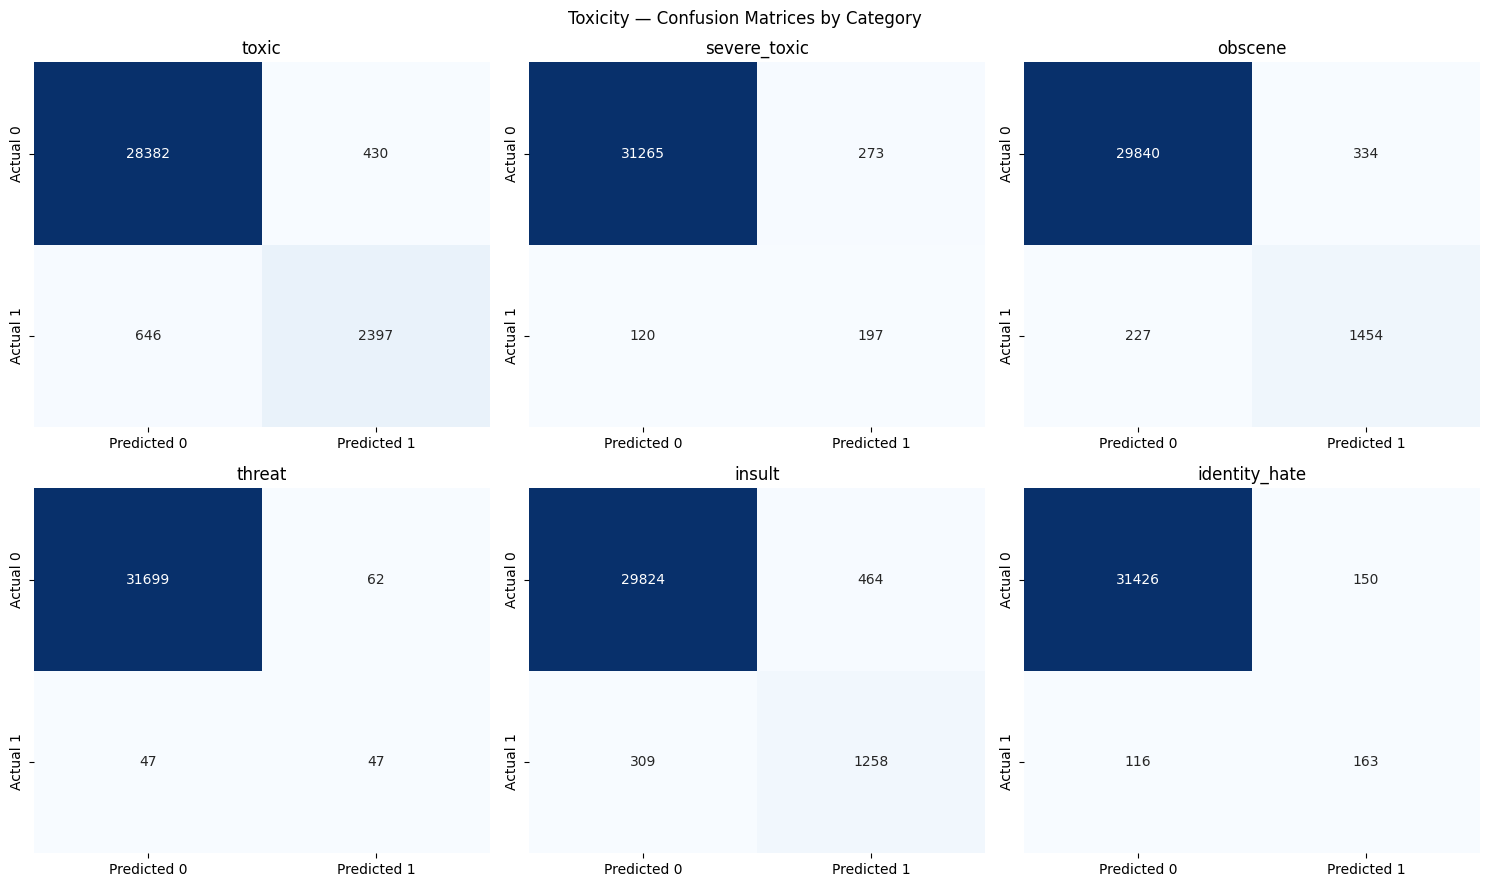

In [12]:
# multi label confusion matrices

mcm = multilabel_confusion_matrix(y_true_tox, y_pred_tox)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for i, ax in enumerate(axes.flatten()):
    sns.heatmap(
        mcm[i],
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Predicted 0", "Predicted 1"],
        yticklabels=["Actual 0", "Actual 1"],
        ax=ax
    )
    ax.set_title(TOX_LABELS[i])

plt.suptitle("Toxicity — Confusion Matrices by Category")
plt.tight_layout()
plt.savefig(f"{OUTPUTS}/08_toxicity_confusion_matrices.png", dpi=150)
plt.show()

In [13]:
# Does common length affect performance

spam["word_count"] = spam["text"].astype(str).str.split().str.len()
tox["word_count"] = tox["text"].astype(str).str.split().str.len()

def length_group(n):
    if n <= 3:
        return "Very short (1–3)"
    elif n <= 10:
        return "Short (4–10)"
    elif n <= 30:
        return "Medium (11–30)"
    return "Long (31+)"

spam["length_group"] = spam["word_count"].apply(length_group)
tox["length_group"] = tox["word_count"].apply(length_group)

spam_length_rows = []

for group, part in spam.groupby("length_group", observed=False):
    if len(part) == 0:
        continue

    spam_length_rows.append({
        "length_group": group,
        "comments": len(part),
        "accuracy": accuracy_score(
            part["label"], part["predicted_label"]
        ),
        "spam_f1": f1_score(
            part["label"], part["predicted_label"],
            pos_label=1, zero_division=0
        )
    })

spam_length_results = pd.DataFrame(spam_length_rows)
display(spam_length_results)

tox_length_rows = []

for group, part in tox.groupby("length_group", observed=False):
    if len(part) == 0:
        continue

    actual = part[TOX_LABELS].values
    predicted = part[[f"pred_{x}" for x in TOX_LABELS]].values

    tox_length_rows.append({
        "length_group": group,
        "comments": len(part),
        "macro_f1": f1_score(
            actual, predicted, average="macro", zero_division=0
        ),
        "micro_f1": f1_score(
            actual, predicted, average="micro", zero_division=0
        )
    })

tox_length_results = pd.DataFrame(tox_length_rows)
display(tox_length_results)

spam_length_results.to_csv(
    f"{REPORTS}/notebook_08_spam_by_length.csv", index=False
)

tox_length_results.to_csv(
    f"{REPORTS}/notebook_08_toxicity_by_length.csv", index=False
)

,length_group,comments,accuracy,spam_f1
0,Long (31+),46,0.956522,0.975000
1,Medium (11–30),103,0.961165,0.960784
2,Short (4–10),139,0.978417,0.972973
3,Very short (1–3),61,1.000000,1.000000


,length_group,comments,macro_f1,micro_f1
0,Long (31+),17725,0.618541,0.724648
1,Medium (11–30),9405,0.667616,0.792881
2,Short (4–10),4558,0.688725,0.832473
3,Very short (1–3),167,0.742130,0.869565


Actual toxicity label counts per comment:


,number_of_labels,comments
0,0,28622
1,1,1293
2,2,649
3,3,864
4,4,343
5,5,78
6,6,6


Predicted toxicity label counts per comment:


,number_of_labels,comments
0,0,29028
1,1,661
2,2,755
3,3,821
4,4,370
5,5,205
6,6,15


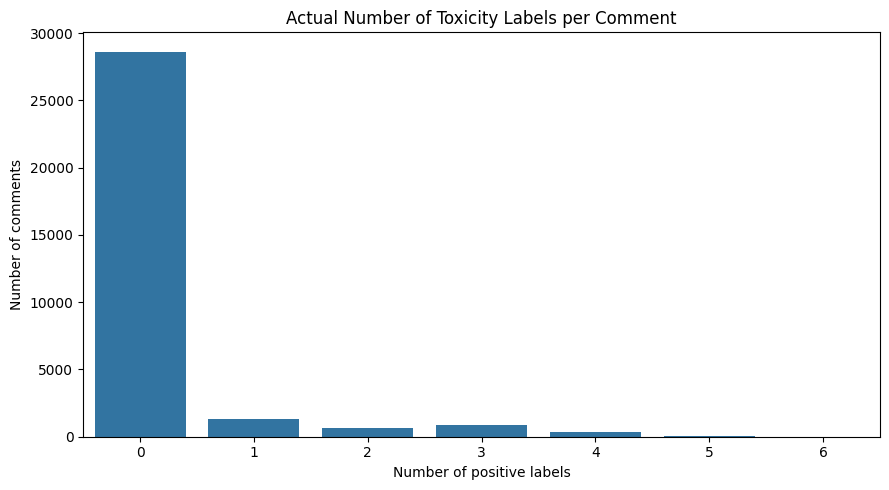

In [14]:
# toxicity label co-occurence

tox["number_of_actual_labels"] = y_true_tox.sum(axis=1)
tox["number_of_predicted_labels"] = y_pred_tox.sum(axis=1)

actual_cooccurrence = (
    tox["number_of_actual_labels"]
    .value_counts()
    .sort_index()
    .rename_axis("number_of_labels")
    .reset_index(name="comments")
)

predicted_cooccurrence = (
    tox["number_of_predicted_labels"]
    .value_counts()
    .sort_index()
    .rename_axis("number_of_labels")
    .reset_index(name="comments")
)

print("Actual toxicity label counts per comment:")
display(actual_cooccurrence)

print("Predicted toxicity label counts per comment:")
display(predicted_cooccurrence)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=actual_cooccurrence,
    x="number_of_labels",
    y="comments"
)
plt.title("Actual Number of Toxicity Labels per Comment")
plt.xlabel("Number of positive labels")
plt.ylabel("Number of comments")
plt.tight_layout()
plt.savefig(f"{OUTPUTS}/08_toxicity_label_cooccurrence.png", dpi=150)
plt.show()

In [15]:
# inspect model confidence on toxicity errors

tox_error_confidence = []

for i, label in enumerate(TOX_LABELS):
    actual = y_true_tox[:, i]
    predicted = y_pred_tox[:, i]
    probability = y_prob_tox[:, i]

    wrong = actual != predicted

    for idx in np.where(wrong)[0]:
        predicted_confidence = (
            probability[idx] if predicted[idx] == 1
            else 1 - probability[idx]
        )

        tox_error_confidence.append({
            "text": tox.iloc[idx]["text"],
            "label": label,
            "actual": int(actual[idx]),
            "predicted": int(predicted[idx]),
            "probability_positive": float(probability[idx]),
            "confidence_in_wrong_prediction": float(predicted_confidence)
        })

tox_error_confidence_df = pd.DataFrame(tox_error_confidence)

print("Highest-confidence wrong predictions:")
display(
    tox_error_confidence_df.sort_values(
        "confidence_in_wrong_prediction",
        ascending=False
    ).head(30)
)

tox_error_confidence_df.to_csv(
    f"{REPORTS}/notebook_08_toxicity_high_confidence_errors.csv",
    index=False
)

Highest-confidence wrong predictions:


,text,label,actual,predicted,probability_positive,confidence_in_wrong_prediction
1242,"""\n\n Where does it say that featured artic...",severe_toxic,1,0,0.000007,0.999993
1276,"a reminder you are late on the rent, puta\n\n]...",severe_toxic,1,0,0.000053,0.999947
3073,Hi sorry to edit this page...i didnt know wher...,identity_hate,1,0,0.000241,0.999759
2467,"""\n\n Where does it say that featured artic...",insult,1,0,0.000261,0.999739
2082,I wish you had died in that earthquake.,threat,1,0,0.000286,0.999714
2597,You only want what YOU feel is important to be...,insult,1,0,0.000371,0.999629
2456,(UTC)\n\nHer husband was still alive in 60's. ...,insult,1,0,0.000371,0.999629
1970,"""\n The various local government areas pages o...",obscene,1,0,0.000392,0.999608
1866,"""\n\nHere's your idea of """"discussion"""" at che...",obscene,1,0,0.000421,0.999579
1959,"Personal attacks (from Annonymous proxy)\nHi, ...",obscene,0,1,0.999570,0.999570


In [16]:
# review the most difficult categories

hardest_categories = tox_per_label.sort_values(
    "f1", ascending=True
).reset_index(drop=True)

print("Toxicity categories ranked from hardest to easiest:")
display(hardest_categories[
    ["label", "support_positive", "precision", "recall", "f1"]
])

print("\nLowest-F1 category:", hardest_categories.iloc[0]["label"])
print("Highest-F1 category:", hardest_categories.iloc[-1]["label"])

Toxicity categories ranked from hardest to easiest:


,label,support_positive,precision,recall,f1
0,threat,94,0.431193,0.500000,0.463054
1,severe_toxic,317,0.419149,0.621451,0.500635
2,identity_hate,279,0.520767,0.584229,0.550676
3,insult,1567,0.730546,0.802808,0.764974
4,toxic,3043,0.847895,0.787709,0.816695
5,obscene,1681,0.813199,0.864961,0.838282



Lowest-F1 category: threat
Highest-F1 category: obscene


In [17]:
# load threshold values

tox_metrics_path = f"{REPORTS}/notebook_07_toxicity_metrics.json"

if os.path.exists(tox_metrics_path):
    with open(tox_metrics_path, "r") as f:
        previous_tox_report = json.load(f)

    saved_thresholds = previous_tox_report.get("thresholds", {})

    print("Saved validation thresholds:")
    for label in TOX_LABELS:
        print(label, ":", saved_thresholds.get(label, "Not found"))
else:
    print("Notebook 07 toxicity metrics JSON not found.")
    saved_thresholds = {}

Saved validation thresholds:
toxic : 0.85
severe_toxic : 0.9
obscene : 0.9
threat : 0.65
insult : 0.8
identity_hate : 0.6


In [18]:
# model comparison

model_comparison = pd.DataFrame([
    {
        "task": "Spam",
        "model": "Logistic Regression — TF-IDF",
        "score_name": "Spam F1",
        "score": 0.95,
        "source": "Previously reported"
    },
    {
        "task": "Spam",
        "model": "DistilBERT",
        "score_name": "Macro-F1",
        "score": spam_metrics["macro_f1"],
        "source": "Notebook 07 saved test predictions"
    },
    {
        "task": "Toxicity",
        "model": "Linear SVM — TF-IDF tuned",
        "score_name": "Macro-F1",
        "score": 0.6087,
        "source": "Previously reported"
    },
    {
        "task": "Toxicity",
        "model": "DistilBERT — default threshold",
        "score_name": "Macro-F1",
        "score": 0.64,
        "source": "Previously reported Notebook 07 result"
    },
    {
        "task": "Toxicity",
        "model": "DistilBERT — optimized thresholds",
        "score_name": "Macro-F1",
        "score": tox_overall_metrics["macro_f1"],
        "source": "Notebook 07 saved test predictions"
    }
])

display(model_comparison)

model_comparison.to_csv(
    f"{REPORTS}/notebook_08_model_comparison.csv",
    index=False
)

,task,model,score_name,score,source
0,Spam,Logistic Regression — TF-IDF,Spam F1,0.950000,Previously reported
1,Spam,DistilBERT,Macro-F1,0.974127,Notebook 07 saved test predictions
2,Toxicity,Linear SVM — TF-IDF tuned,Macro-F1,0.608700,Previously reported
3,Toxicity,DistilBERT — default threshold,Macro-F1,0.640000,Previously reported Notebook 07 result
4,Toxicity,DistilBERT — optimized thresholds,Macro-F1,0.655719,Notebook 07 saved test predictions


In [19]:
# save report

summary = {
    "notebook": "08_Comparative_Evaluation_and_Error_Analysis",
    "spam": {
        "test_rows_analysed": int(len(spam)),
        "metrics": spam_metrics,
        "confusion_matrix": cm_spam.tolist(),
        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp),
        "error_count": int(len(spam_errors))
    },
    "toxicity": {
        "test_rows_analysed": int(len(tox)),
        "overall_metrics": tox_overall_metrics,
        "per_label_metrics": tox_per_label.to_dict(orient="records"),
        "error_count": int(len(tox_errors)),
        "hardest_category": str(hardest_categories.iloc[0]["label"]),
        "easiest_category": str(hardest_categories.iloc[-1]["label"])
    },
    "artifacts": {
        "spam_errors": f"{REPORTS}/notebook_08_spam_errors.csv",
        "toxicity_errors": f"{REPORTS}/notebook_08_toxicity_errors.csv",
        "toxicity_high_confidence_errors":
            f"{REPORTS}/notebook_08_toxicity_high_confidence_errors.csv",
        "model_comparison": f"{REPORTS}/notebook_08_model_comparison.csv"
    }
}

report_path = f"{REPORTS}/notebook_08_error_analysis_summary.json"

with open(report_path, "w") as f:
    json.dump(summary, f, indent=2)

print("Saved report:", report_path)
print(json.dumps(summary, indent=2))

Saved report: /content/drive/MyDrive/Smart_Comment_Classifier/datasets/reports/notebook_08_error_analysis_summary.json
{
  "notebook": "08_Comparative_Evaluation_and_Error_Analysis",
  "spam": {
    "test_rows_analysed": 349,
    "metrics": {
      "accuracy": 0.9742120343839542,
      "macro_precision": 0.9756178141932074,
      "macro_recall": 0.9734280452512496,
      "macro_f1": 0.9741270664986286,
      "spam_precision": 0.9937888198757764,
      "spam_recall": 0.9523809523809523,
      "spam_f1": 0.9726443768996961,
      "spam_roc_auc": 0.9944751381215469,
      "spam_average_precision": 0.9951311457896277
    },
    "confusion_matrix": [
      [
        180,
        1
      ],
      [
        8,
        160
      ]
    ],
    "true_negative": 180,
    "false_positive": 1,
    "false_negative": 8,
    "true_positive": 160,
    "error_count": 9
  },
  "toxicity": {
    "test_rows_analysed": 31855,
    "overall_metrics": {
      "macro_f1": 0.6557193880689568,
      "micro_f1": 0.

In [20]:
expected_files = [
    f"{REPORTS}/notebook_08_spam_errors.csv",
    f"{REPORTS}/notebook_08_toxicity_errors.csv",
    f"{REPORTS}/notebook_08_toxicity_per_label.csv",
    f"{REPORTS}/notebook_08_toxicity_high_confidence_errors.csv",
    f"{REPORTS}/notebook_08_spam_by_length.csv",
    f"{REPORTS}/notebook_08_toxicity_by_length.csv",
    f"{REPORTS}/notebook_08_model_comparison.csv",
    f"{REPORTS}/notebook_08_error_analysis_summary.json",
    f"{OUTPUTS}/08_spam_confusion_matrix.png",
    f"{OUTPUTS}/08_spam_confidence_analysis.png",
    f"{OUTPUTS}/08_toxicity_category_f1.png",
    f"{OUTPUTS}/08_toxicity_confusion_matrices.png",
    f"{OUTPUTS}/08_toxicity_label_cooccurrence.png"
]

for path in expected_files:
    print(("OK" if os.path.exists(path) else "MISSING"), path)

print("\nNotebook 08 completed.")

OK /content/drive/MyDrive/Smart_Comment_Classifier/datasets/reports/notebook_08_spam_errors.csv
OK /content/drive/MyDrive/Smart_Comment_Classifier/datasets/reports/notebook_08_toxicity_errors.csv
OK /content/drive/MyDrive/Smart_Comment_Classifier/datasets/reports/notebook_08_toxicity_per_label.csv
OK /content/drive/MyDrive/Smart_Comment_Classifier/datasets/reports/notebook_08_toxicity_high_confidence_errors.csv
OK /content/drive/MyDrive/Smart_Comment_Classifier/datasets/reports/notebook_08_spam_by_length.csv
OK /content/drive/MyDrive/Smart_Comment_Classifier/datasets/reports/notebook_08_toxicity_by_length.csv
OK /content/drive/MyDrive/Smart_Comment_Classifier/datasets/reports/notebook_08_model_comparison.csv
OK /content/drive/MyDrive/Smart_Comment_Classifier/datasets/reports/notebook_08_error_analysis_summary.json
OK /content/drive/MyDrive/Smart_Comment_Classifier/outputs/08_spam_confusion_matrix.png
OK /content/drive/MyDrive/Smart_Comment_Classifier/outputs/08_spam_confidence_analysis